# 04 — Geospatial Analysis

**Module 03.** Where is historical seismic activity concentrated, and how do
named regions compare?

Everything here is a **historical activity indicator** — not hazard, and not
risk. Disaster risk additionally requires *exposure* (people, infrastructure)
and *vulnerability*, which this project deliberately does not model.

The grid is shared with Module 02, so a cell on this map is the same cell a
forecast row refers to.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from seismo.config import load_config
from seismo.geospatial.analysis import (
    NAMED_REGIONS,
    filter_region,
    grid_from_config,
    hotspot_cells,
    spatial_density,
)

In [2]:
# Locate the project root so data paths resolve whether the notebook runs
# interactively from the repo root or is executed by nbconvert from notebooks/.
# (Imports above are unaffected — `seismo` is installed as a package.)
for _candidate in [Path.cwd(), *Path.cwd().parents]:
    if (_candidate / "config" / "config.yaml").is_file():
        os.chdir(_candidate)
        break

sns.set_theme(style="whitegrid", font_scale=1.1)

# Project design system
NAVY = "#14263D"
ACCENT = "#2583A6"
LIGHT = "#E9EEF3"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "text.color": NAVY,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
})

cfg = load_config()
grid = grid_from_config(cfg)
events = pd.read_parquet("data/processed/earthquakes.parquet")
activity = pd.read_parquet("data/features/cell_activity.parquet")

print(f"Events:      {len(events):,}")
print(f"Active cells: {len(activity):,}  ({grid.cell_size_deg}° grid)")
print(f"Period:      {events['time'].min().date()} → {events['time'].max().date()}")

Events:      707,438
Active cells: 11,503  (1.0° grid)
Period:      2000-01-01 → 2026-11-15


## 1. Global spatial density

Pre-aggregated into a 2-D histogram rather than plotting 707k raw points —
the same technique the Streamlit map uses to stay responsive.

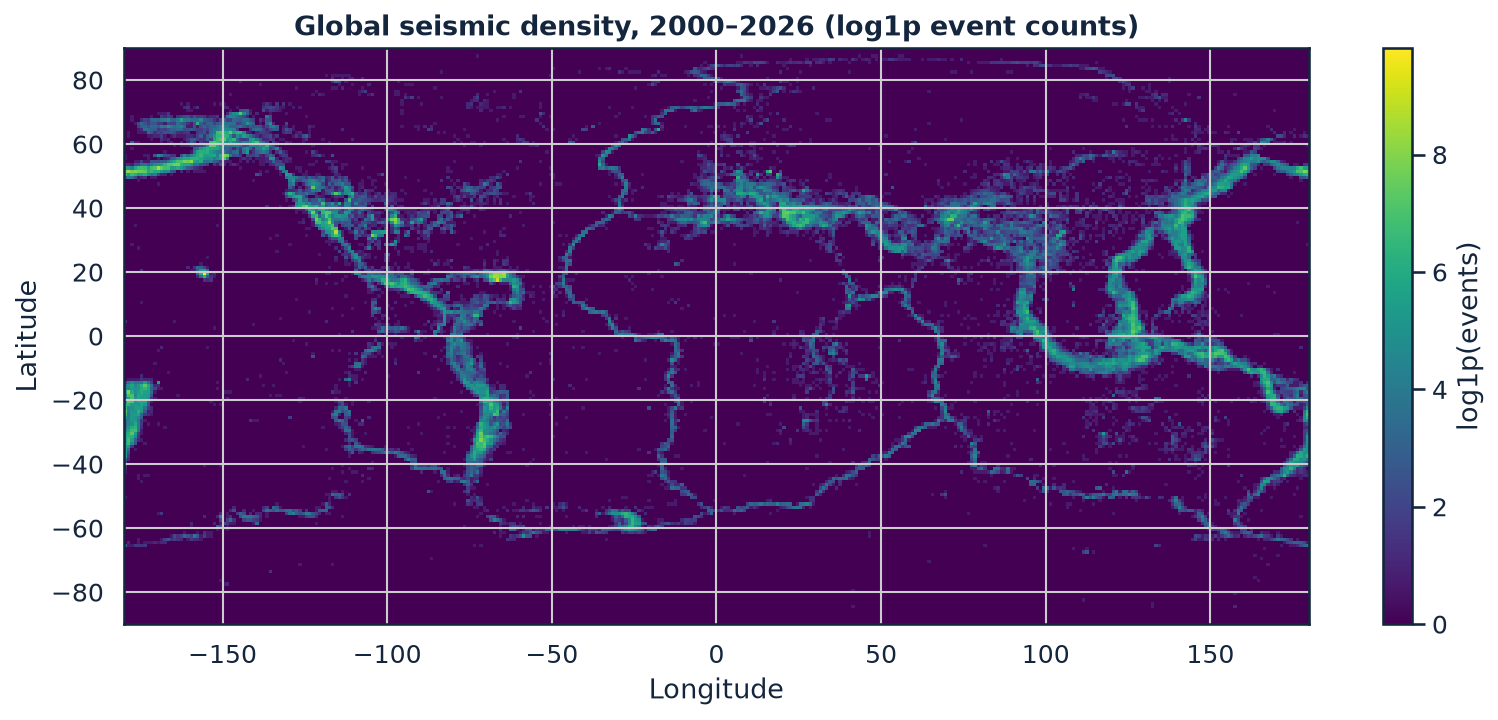

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
density = spatial_density(events, grid, lat_bins=180, lon_bins=360)

im = ax.imshow(
    np.log1p(density),
    origin="lower",
    extent=[-180, 180, -90, 90],
    aspect="auto",
    cmap="viridis",
    interpolation="nearest",
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Global seismic density, 2000–2026 (log1p event counts)")
fig.colorbar(im, ax=ax, label="log1p(events)")
fig.tight_layout()
fig.savefig("reports/figures/geo_spatial_density.png", bbox_inches="tight")
plt.show()

The ring of activity around the Pacific ("Ring of Fire"), the Mid-Atlantic
Ridge, and the Alpine–Himalayan belt are all visible — a good external check
that our grid assignment is correct.

## 2. The most active cells

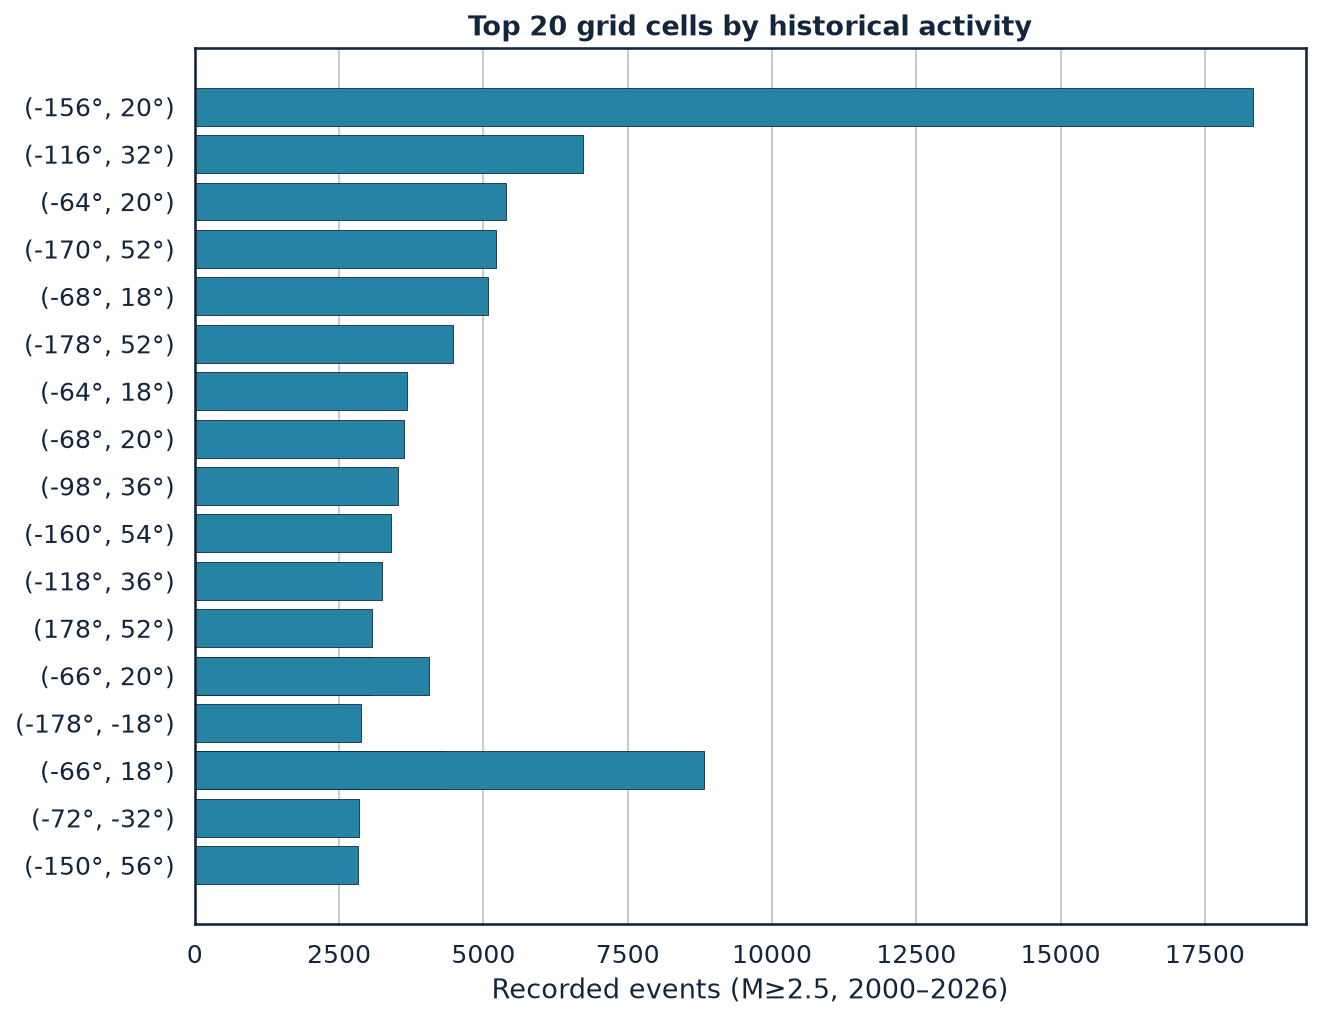

 cell_id  n_events  mean_mag  max_mag  latitude_center  longitude_center
   39264     18328  2.807671      6.7             19.5            -155.5
   38633      8816  2.841619      6.4             17.5             -66.5
   43984      6723  2.948433      7.2             32.5            -115.5
   39355      5391  3.270940      6.1             19.5             -64.5
   51130      5226  3.045285      6.9             52.5            -169.5
   38992      5079  2.952733      5.8             18.5             -67.5
   50761      4477  3.045823      6.5             51.5            -178.5
   38993      4334  2.851278      5.6             18.5             -66.5
   39353      4065  3.072854      6.4             19.5             -66.5
   38995      3680  3.098644      5.7             18.5             -64.5


In [4]:
top = hotspot_cells(activity, top_n=20)

fig, ax = plt.subplots(figsize=(9, 7))
labels = [f"({r.longitude_center:.0f}°, {r.latitude_center:.0f}°)"
          for r in top.itertuples()]
ax.barh(labels[::-1], top["n_events"][::-1], color=ACCENT, edgecolor=NAVY, linewidth=0.4)
ax.set_xlabel("Recorded events (M≥2.5, 2000–2026)")
ax.set_title("Top 20 grid cells by historical activity")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("reports/figures/geo_top_cells.png", bbox_inches="tight")
plt.show()

print(top.head(10).to_string(index=False))

> **Caveat:** raw counts partly reflect *monitoring density*. A well-instrumented
region records more small events. Counts are therefore an activity indicator,
not a like-for-like measure of seismicity between regions.

## 3. Named region comparison

Regions are bounding boxes (defined in `seismo.geospatial.analysis`) that
deliberately avoid crossing the antimeridian.

In [5]:
rows = []
for name in NAMED_REGIONS:
    sub = filter_region(events, name)
    if sub.empty:
        continue
    span_years = (sub["time"].max() - sub["time"].min()).total_seconds() / (365.25 * 86400)
    rows.append({
        "region": name,
        "events": len(sub),
        "events_per_year": len(sub) / max(span_years, 1e-9),
        "mean_mag": sub["mag"].mean(),
        "max_mag": sub["mag"].max(),
        "mean_depth": sub["depth"].mean(),
        "pct_ge_4p5": 100 * (sub["mag"] >= 4.5).mean(),
    })

regions = pd.DataFrame(rows).sort_values("events", ascending=False)
regions

,region,events,events_per_year,mean_mag,max_mag,mean_depth,pct_ge_4p5
8,Alaska,86931,3234.749551,2.995844,8.2,35.986492,2.559501
1,Indonesia,57197,2128.641469,4.505913,9.1,79.945467,48.756054
7,California & US West,43477,1617.819290,2.929010,7.2,7.888847,0.906226
5,Chile & Peru,40891,1521.575185,4.002145,8.8,77.582925,24.817197
10,Greece & Italy,33346,1241.179111,3.397328,7.0,19.140719,6.246626
0,Japan,24896,926.717404,4.481501,9.1,64.398103,47.626125
3,Papua New Guinea & Solomons,22345,831.650741,4.560173,8.1,62.562914,54.137391
6,Central America & Mexico,21385,795.822786,4.241262,8.2,45.542366,23.923311
11,Hawaii,20307,755.794558,2.821426,6.9,7.370528,0.384104
2,Philippines,15622,581.319350,4.555806,7.8,70.394382,56.196390


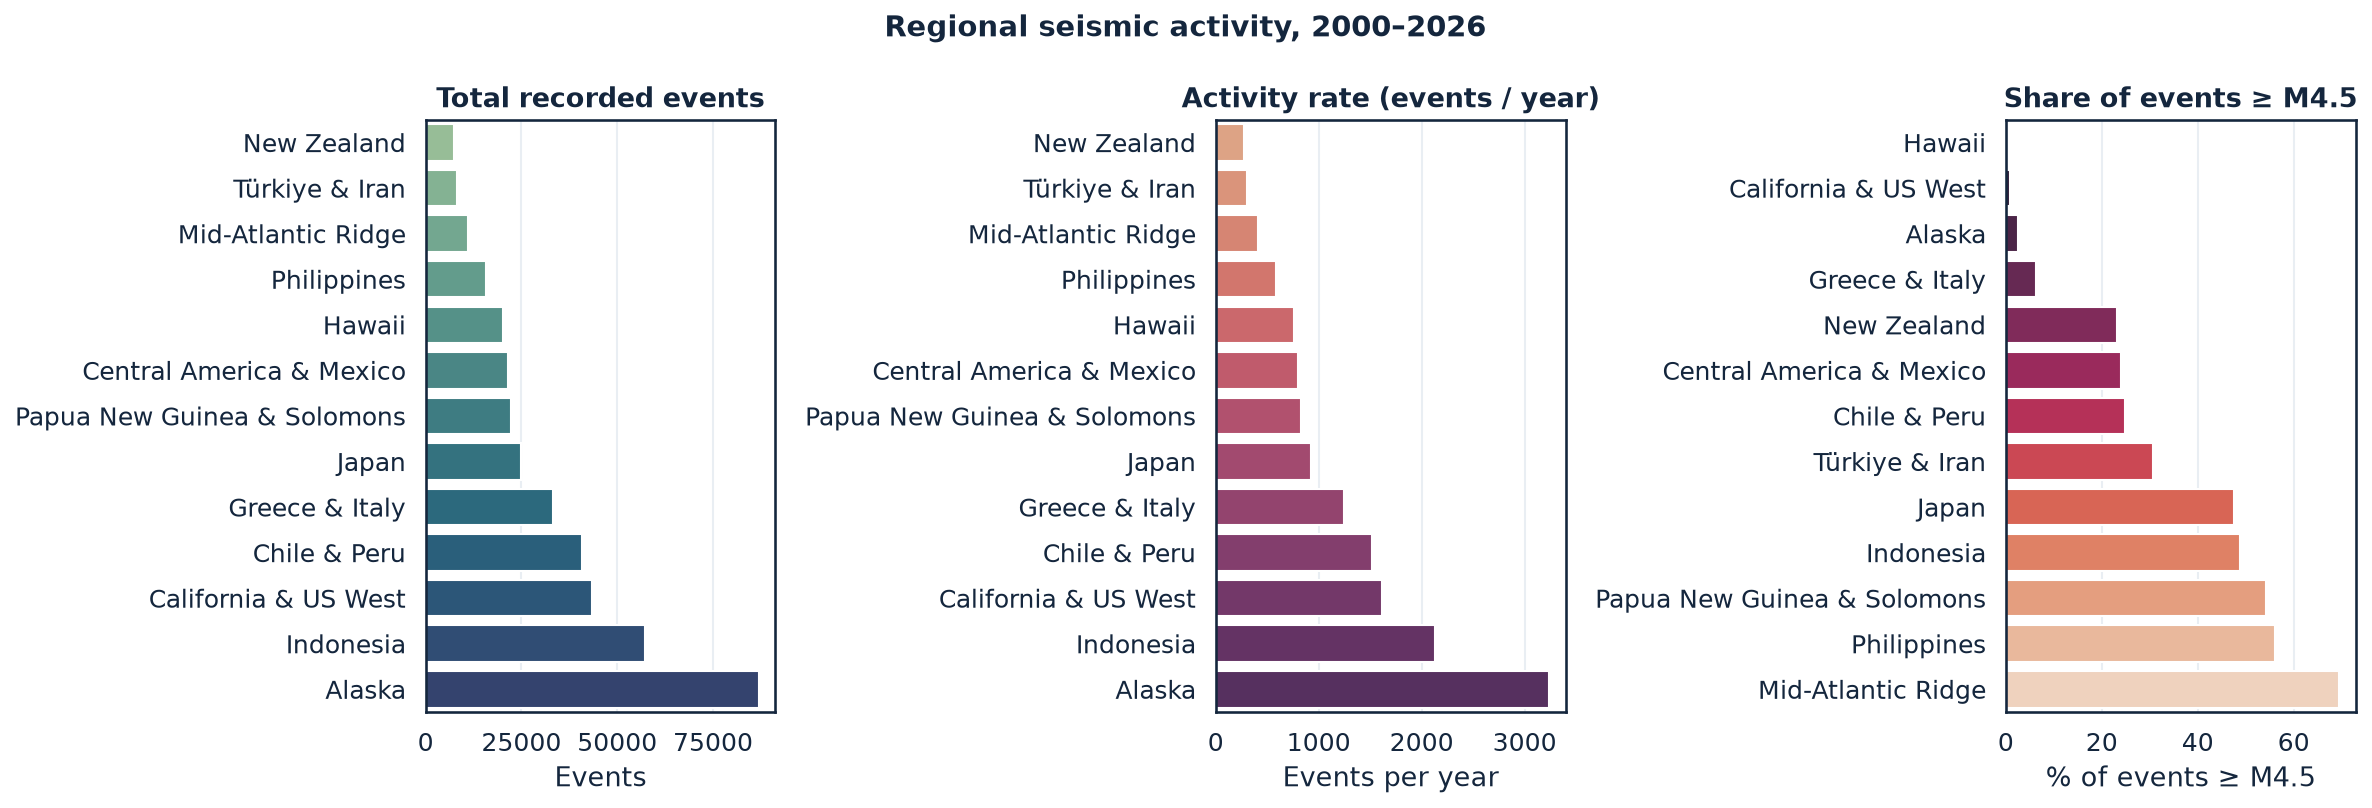

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

order = regions.sort_values("events")["region"]

sns.barplot(data=regions.sort_values("events"), y="region", x="events",
            hue="region", palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Total recorded events")
axes[0].set_xlabel("Events")
axes[0].set_ylabel("")

sns.barplot(data=regions.sort_values("events_per_year"), y="region",
            x="events_per_year", hue="region", palette="flare", legend=False,
            ax=axes[1])
axes[1].set_title("Activity rate (events / year)")
axes[1].set_xlabel("Events per year")
axes[1].set_ylabel("")

sns.barplot(data=regions.sort_values("pct_ge_4p5"), y="region", x="pct_ge_4p5",
            hue="region", palette="rocket", legend=False, ax=axes[2])
axes[2].set_title("Share of events ≥ M4.5")
axes[2].set_xlabel("% of events ≥ M4.5")
axes[2].set_ylabel("")

for ax in axes:
    ax.grid(axis="x", color=LIGHT)
    ax.grid(axis="y", visible=False)

fig.suptitle("Regional seismic activity, 2000–2026", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("reports/figures/geo_region_comparison.png", bbox_inches="tight")
plt.show()

## 4. Depth structure by region

Depth separates tectonic settings: shallow crustal seismicity versus deep
subduction-zone events (>300 km).

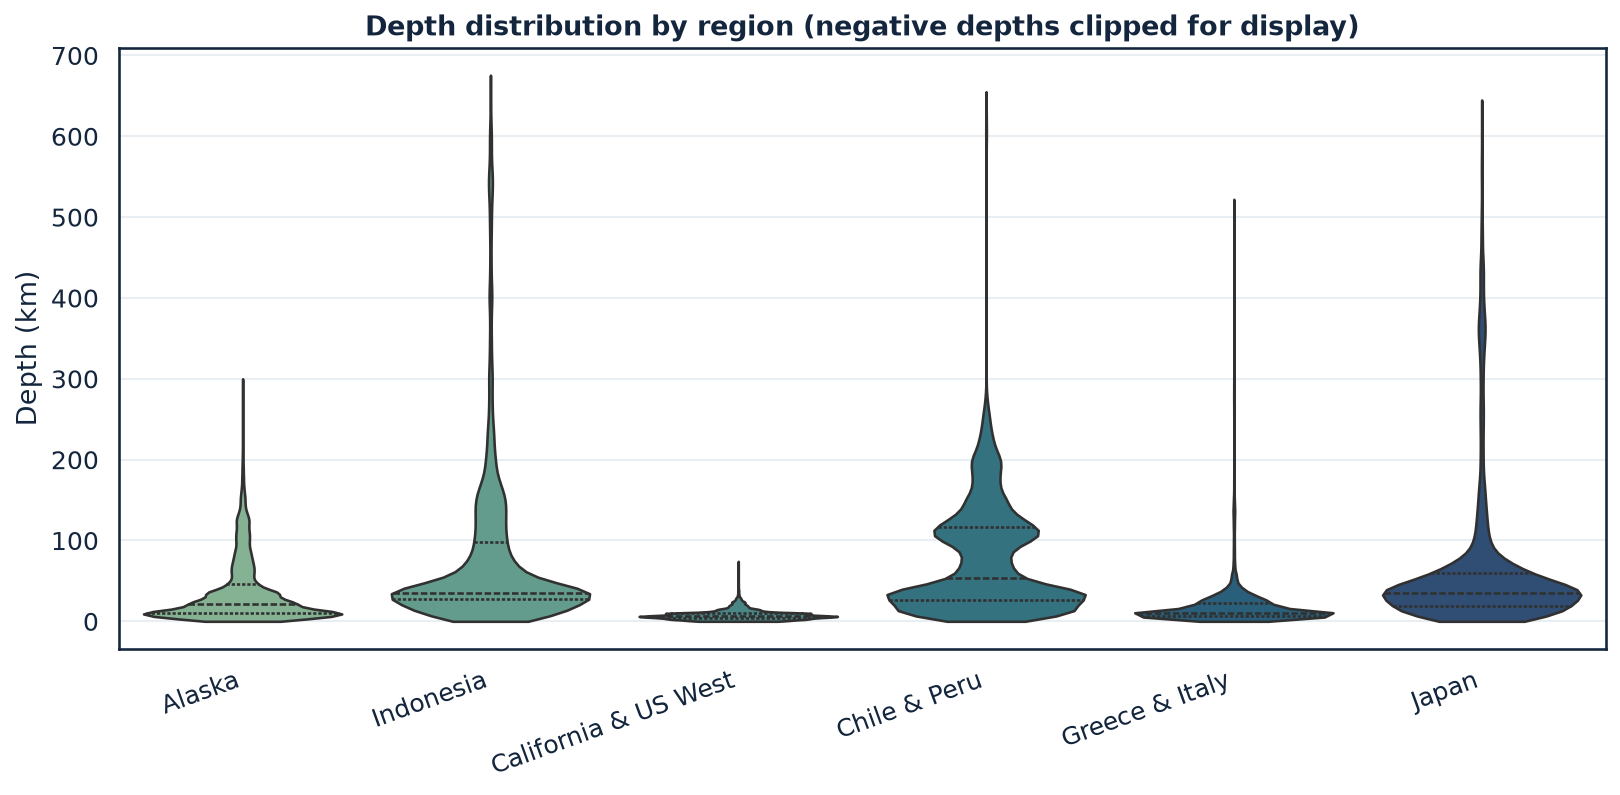

In [7]:
focus = regions.sort_values("events", ascending=False).head(6)["region"].tolist()
depth_rows = []
for name in focus:
    sub = filter_region(events, name)
    depth_rows.append(pd.DataFrame({"region": name, "depth": sub["depth"].clip(lower=0)}))

depth_df = pd.concat(depth_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.violinplot(data=depth_df, x="region", y="depth", hue="region",
               inner="quartile", palette="crest", cut=0, ax=ax,
               legend=False, density_norm="width")
ax.set_xlabel("")
ax.set_ylabel("Depth (km)")
ax.set_title("Depth distribution by region (negative depths clipped for display)")
ax.grid(axis="y", color=LIGHT)
ax.grid(axis="x", visible=False)
plt.xticks(rotation=20, ha="right")
fig.tight_layout()
fig.savefig("reports/figures/geo_depth_by_region.png", bbox_inches="tight")
plt.show()

## 5. Activity rate versus magnitude

Do high-count cells also produce larger events? This checks whether *frequency*
and *severity* are the same signal or two different ones.

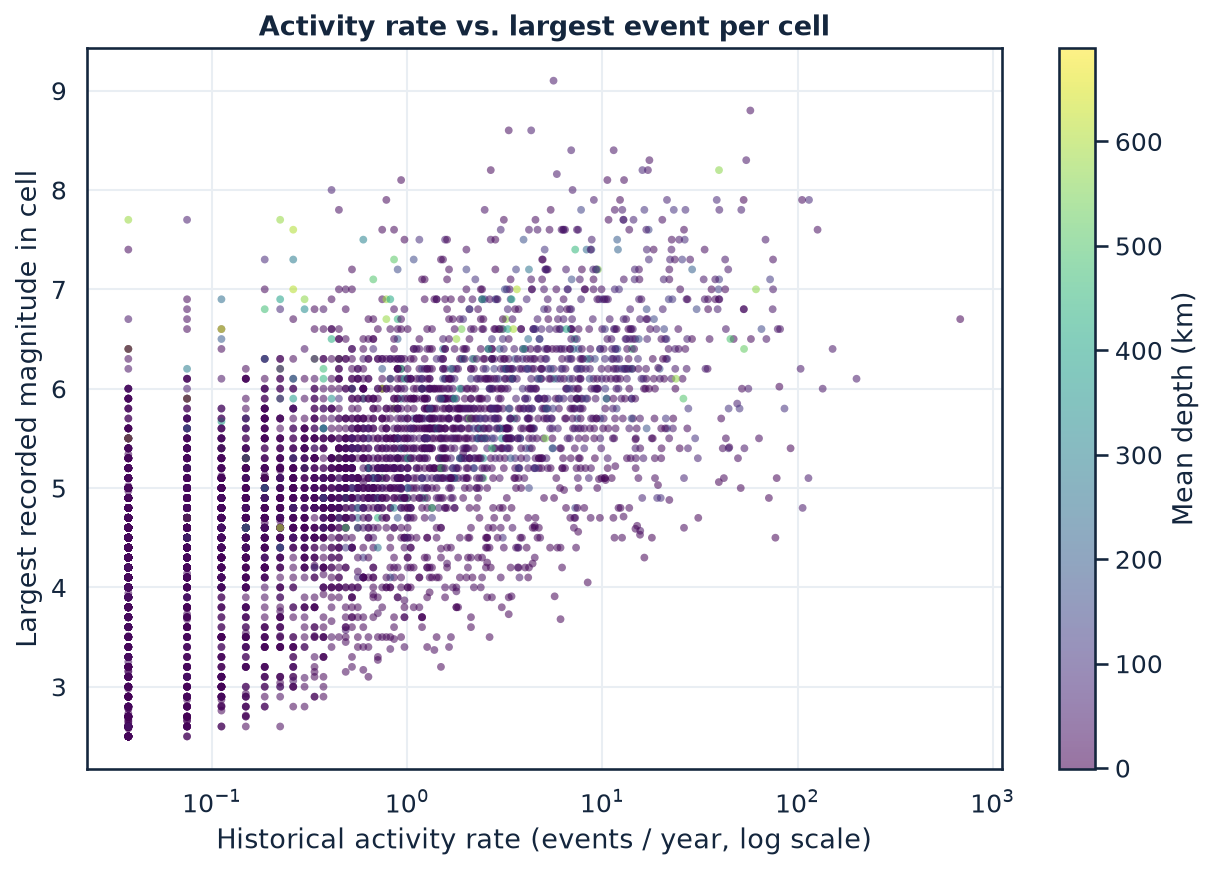

Correlation(log10 rate, max magnitude) = 0.645


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 6))
sample = activity.sample(n=min(6000, len(activity)), random_state=cfg.seed)
sc = ax.scatter(
    sample["events_per_year"], sample["max_mag"],
    c=sample["mean_depth"], cmap="viridis",
    s=14, alpha=0.55, linewidths=0,
)
ax.set_xscale("log")
ax.set_xlabel("Historical activity rate (events / year, log scale)")
ax.set_ylabel("Largest recorded magnitude in cell")
ax.set_title("Activity rate vs. largest event per cell")
fig.colorbar(sc, ax=ax, label="Mean depth (km)")
ax.grid(color=LIGHT)
fig.tight_layout()
fig.savefig("reports/figures/geo_rate_vs_magnitude.png", bbox_inches="tight")
plt.show()

corr = np.corrcoef(
    np.log10(sample["events_per_year"]),
    sample["max_mag"],
)[0, 1]
print(f"Correlation(log10 rate, max magnitude) = {corr:.3f}")

## 6. Conclusions

*Activity rate and event size are related but not identical signals* — a cell
can be extremely active without having produced its largest event yet, and
quiet cells still record occasional large events. This is precisely why
Module 02 models **probability** rather than extrapolating counts.

In [9]:
summary = {
    "active_cells": int(len(activity)),
    "busiest_cell_events": int(activity["n_events"].max()),
    "regions_compared": int(len(regions)),
    "top_region": str(regions.iloc[0]["region"]),
    "top_region_events": int(regions.iloc[0]["events"]),
    "log_rate_vs_maxmag_corr": round(float(corr), 3),
}
summary

{'active_cells': 11503,
 'busiest_cell_events': 18328,
 'regions_compared': 13,
 'top_region': 'Alaska',
 'top_region_events': 86931,
 'log_rate_vs_maxmag_corr': 0.645}